In [1]:
!pip install lightgbm --quiet
!pip install catboost --quiet

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.1/97.1 MB 8.5 MB/s eta 0:00:00


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
import warnings
import time
import joblib
warnings.filterwarnings('ignore')

from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.model_selection import cross_val_score
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor, AdaBoostRegressor
from sklearn.neighbors import KNeighborsRegressor
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.impute import SimpleImputer

from xgboost import XGBRegressor
from lightgbm import LGBMRegressor
from catboost import CatBoostRegressor

sns.set_theme(style='whitegrid', palette='muted')
plt.rcParams.update({'figure.dpi': 120, 'axes.titlesize': 12})

In [3]:
df = pd.read_csv('dynamic_pricing_model_ready.csv')
print('Shape:', df.shape)
print('Columns:', df.columns.tolist())
print('\n')
df.head()

Shape: (253009, 11)
Columns: ['date', 'StockCode', 'price', 'demand', 'revenue', 'n_txn', 'month_dt', 'dow', 'month', 'elasticity', 'price_sensitive']




,date,StockCode,price,demand,revenue,n_txn,month_dt,dow,month,elasticity,price_sensitive
0,2009-12-01,10002,0.850,12,10.20,1,2009-12,1,12,-2.954460,True
1,2009-12-01,10120,0.210,60,12.60,1,2009-12,1,12,-7.934931,True
2,2009-12-01,10125,1.275,5,5.10,2,2009-12,1,12,-3.099670,True
3,2009-12-01,10133,0.850,6,5.10,1,2009-12,1,12,-3.345425,True
4,2009-12-01,10135,1.250,17,21.25,3,2009-12,1,12,-2.062264,True


In [4]:
print('           Dtypes:\n')
print(df.dtypes)
print('\n         Null counts:')
print(df.isnull().sum())

           Dtypes:

date                object
StockCode           object
price              float64
demand               int64
revenue            float64
n_txn                int64
month_dt            object
dow                  int64
month                int64
elasticity         float64
price_sensitive       bool
dtype: object

         Null counts:
date                   0
StockCode              0
price                  0
demand                 0
revenue                0
n_txn                  0
month_dt               0
dow                    0
month                  0
elasticity         45379
price_sensitive        0
dtype: int64


In [5]:
# Fill elasticity NaNs (45k rows had NaN that corrupt model inputs)
df['elasticity'] = df['elasticity'].fillna(0)

#Cast bool to int
df['price_sensitive'] = df['price_sensitive'].astype(int)

# Label encode StockCode
le = LabelEncoder()
df['StockCode_enc'] = le.fit_transform(df['StockCode'].astype(str))

# Log-price feature (demand vs price is non-linear)
df['log_price'] = np.log1p(df['price'])

# Interaction features
df['price_x_month'] = df['price'] * df['month']
df['price_x_dow']   = df['price'] * df['dow']

# Final feature set
FEATURES = [
    'price',           # raw price
    'log_price',       # log-transformed price (captures non-linear demand)
    'month',           # seasonality
    'dow',             # day of week
    'week',            # week of year
    'n_txn',           # number of invoices on that day for this SKU
    'elasticity',      # price elasticity of this SKU (from EDA)
    'price_sensitive', # binary: is this SKU elastic?
    'StockCode_enc',   # product identity
    'price_x_month',   # price × seasonality interaction
    'price_x_dow',     # price × day-of-week interaction
]

TARGET = 'demand'

print(f'Features: {len(FEATURES)}')
print(FEATURES)
print(f'\nTarget: {TARGET}')
print(f'Target range: {df[TARGET].min()} – {df[TARGET].max()}, mean={df[TARGET].mean():.2f}')

Features: 11
['price', 'log_price', 'month', 'dow', 'week', 'n_txn', 'elasticity', 'price_sensitive', 'StockCode_enc', 'price_x_month', 'price_x_dow']

Target: demand
Target range: 1 – 240, mean=16.34


## Train / Test Split

**Temporal split** — data is sorted by date, so `iloc[:80%]` naturally gives past data for training and future data for testing. This is correct for time-series. A random split would leak future information into training.

In [6]:
df = df.sort_values('date').reset_index(drop=True)

df['week'] = pd.to_datetime(df['date']).dt.isocalendar().week.astype(int)

split_index = int(len(df) * 0.8)
train_df = df.iloc[:split_index]
test_df  = df.iloc[split_index:]

X_train = train_df[FEATURES]
y_train = train_df[TARGET]
X_test  = test_df[FEATURES]
y_test  = test_df[TARGET]

print(f'Train: {X_train.shape}  |  dates: {train_df["date"].min()} → {train_df["date"].max()}')
print(f'Test:  {X_test.shape}   |  dates: {test_df["date"].min()} → {test_df["date"].max()}')

Train: (202407, 11)  |  dates: 2009-12-01 → 2010-10-18
Test:  (50602, 11)   |  dates: 2010-10-18 → 2010-12-09


## 5. Preprocessing — Scaling

StandardScaler is applied after the split (fit on train only, transform both) to prevent data leakage.

In [7]:
scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s  = scaler.transform(X_test)

print('X_train scaled shape:', X_train_s.shape)
print('X_test  scaled shape:', X_test_s.shape)

X_train scaled shape: (202407, 11)
X_test  scaled shape: (50602, 11)


## 6. Evaluation Helper

In [8]:
def evaluate_model(name, model, X_tr, y_tr, X_te, y_te, verbose=True):

    t0 = time.time()
    model.fit(X_tr, y_tr)
    elapsed = time.time() - t0

    yp_tr = model.predict(X_tr)
    yp_te = model.predict(X_te)

    metrics = {
        'model':        name,
        'train_r2':     r2_score(y_tr, yp_tr),
        'test_r2':      r2_score(y_te, yp_te),
        'test_rmse':    np.sqrt(mean_squared_error(y_te, yp_te)),
        'test_mae':     mean_absolute_error(y_te, yp_te),
        'train_sec':    elapsed,
    }

    if verbose:
        overfit = metrics['train_r2'] - metrics['test_r2']
        print(f"\n{'='*55}")
        print(f" {name}")
        print(f"{'='*55}")
        print(f"  Train R²  : {metrics['train_r2']:.4f}")
        print(f"  Test  R²  : {metrics['test_r2']:.4f}  {'⚠ overfitting' if overfit > 0.15 else '✓'}")
        print(f"  Test RMSE : {metrics['test_rmse']:.2f}")
        print(f"  Test MAE  : {metrics['test_mae']:.2f}")
        print(f"  Train time: {elapsed:.1f}s")

    return metrics, model, yp_te

results = []
print('Evaluation helper ready.')

Evaluation helper ready.


## 7. Linear Models

In [9]:
m, _, _ = evaluate_model('Linear Regression', LinearRegression(),
                          X_train_s, y_train, X_test_s, y_test)
results.append(m)


 Linear Regression
  Train R²  : 0.3178
  Test  R²  : 0.3794  ✓
  Test RMSE : 22.39
  Test MAE  : 13.27
  Train time: 0.3s


In [10]:
m, _, _ = evaluate_model('Ridge (alpha=10)', Ridge(alpha=10),
                          X_train_s, y_train, X_test_s, y_test)
results.append(m)


 Ridge (alpha=10)
  Train R²  : 0.3178
  Test  R²  : 0.3795  ✓
  Test RMSE : 22.39
  Test MAE  : 13.27
  Train time: 0.1s


In [11]:
m, lasso_model, _ = evaluate_model('Lasso (alpha=0.1)', Lasso(alpha=0.1, max_iter=1000),
                                    X_train_s, y_train, X_test_s, y_test)
results.append(m)


 Lasso (alpha=0.1)
  Train R²  : 0.3171
  Test  R²  : 0.3811  ✓
  Test RMSE : 22.36
  Test MAE  : 13.16
  Train time: 6.1s


In [12]:
# Lasso feature selection — which features did it zero out?
lasso_coefs = pd.Series(lasso_model.coef_, index=FEATURES).sort_values(key=abs, ascending=False)
print('Lasso coefficients (sorted by |magnitude|):')
print(lasso_coefs.round(4))
print(f'\nFeatures zeroed out by Lasso: {(lasso_coefs == 0).sum()}')

Lasso coefficients (sorted by |magnitude|):
log_price         -14.5427
n_txn              13.3751
price               6.8015
dow                -0.8002
price_x_dow         0.5153
elasticity         -0.2942
StockCode_enc       0.2357
month              -0.0000
week               -0.0000
price_sensitive     0.0000
price_x_month      -0.0000
dtype: float64

Features zeroed out by Lasso: 4


In [13]:
# m, _, _ = evaluate_model('KNN (k=10, ball_tree)',
#                           KNeighborsRegressor(n_neighbors=10, algorithm='ball_tree', n_jobs=-1),
#                           X_train_s, y_train, X_test_s, y_test)
# results.append(m)

# takes too much time but not getting result
  # Train R²  : 0.4690
  # Test  R²  : 0.3728  ✓
  # Test RMSE : 22.51
  # Test MAE  : 11.98

## 9. Ensemble Models

In [14]:
m, _, _ = evaluate_model('AdaBoost',
                          AdaBoostRegressor(n_estimators=100, random_state=42),
                          X_train_s, y_train, X_test_s, y_test)
results.append(m)


 AdaBoost
  Train R²  : 0.1247
  Test  R²  : 0.0595  ✓
  Test RMSE : 27.56
  Test MAE  : 20.14
  Train time: 15.5s


In [15]:
m, rf_model, _ = evaluate_model('Random Forest',
                                  RandomForestRegressor(n_estimators=100, max_depth=8,
                                                        n_jobs=-1, random_state=42),
                                  X_train_s, y_train, X_test_s, y_test)
results.append(m)


 Random Forest
  Train R²  : 0.4924
  Test  R²  : 0.4777  ✓
  Test RMSE : 20.54
  Test MAE  : 11.07
  Train time: 54.1s


## 10. Gradient Boosting Models

These are the best performers for tabular demand forecasting.

In [16]:
# XGBoost
m, xgb_model, _ = evaluate_model('XGBoost',
                                   XGBRegressor(n_estimators=200, max_depth=5,
                                                learning_rate=0.05, subsample=0.8,
                                                n_jobs=-1, random_state=42, verbosity=0),
                                   X_train_s, y_train, X_test_s, y_test)
results.append(m)


 XGBoost
  Train R²  : 0.5075
  Test  R²  : 0.5108  ✓
  Test RMSE : 19.88
  Test MAE  : 10.14
  Train time: 2.5s


In [17]:
# LightGBM — fastest of the boosting trio, often best R²
m, lgbm_model, lgbm_preds = evaluate_model('LightGBM',
                                             LGBMRegressor(n_estimators=200, max_depth=5,
                                                           learning_rate=0.05, n_jobs=-1,
                                                           random_state=42, verbose=-1),
                                             X_train_s, y_train, X_test_s, y_test)
results.append(m)


 LightGBM
  Train R²  : 0.5197
  Test  R²  : 0.5169  ✓
  Test RMSE : 19.75
  Test MAE  : 10.05
  Train time: 2.3s


In [18]:
# CatBoost
m, cb_model, _ = evaluate_model('CatBoost',
                                  CatBoostRegressor(iterations=200, depth=5,
                                                    learning_rate=0.05, random_state=42,
                                                    verbose=False),
                                  X_train_s, y_train, X_test_s, y_test)
results.append(m)


 CatBoost
  Train R²  : 0.4461
  Test  R²  : 0.4713  ✓
  Test RMSE : 20.66
  Test MAE  : 10.94
  Train time: 6.7s


## 11. Results Comparison

In [19]:
# results DataFrame now properly populated (was empty in original)
results_df = pd.DataFrame(results).sort_values('test_r2', ascending=False).reset_index(drop=True)
results_df['overfit_gap'] = (results_df['train_r2'] - results_df['test_r2']).round(4)
print(results_df[['model','train_r2','test_r2','test_rmse','test_mae','overfit_gap','train_sec']].to_string(index=False))

            model  train_r2  test_r2  test_rmse  test_mae  overfit_gap  train_sec
         LightGBM  0.519696 0.516913  19.752096 10.053418       0.0028   2.296471
          XGBoost  0.507525 0.510771  19.877274 10.136891      -0.0032   2.457569
    Random Forest  0.492418 0.477742  20.537282 11.068725       0.0147  54.086083
         CatBoost  0.446098 0.471341  20.662762 10.937781      -0.0252   6.708651
Lasso (alpha=0.1)  0.317148 0.381096  22.356939 13.156348      -0.0639   6.107083
 Ridge (alpha=10)  0.317808 0.379459  22.386488 13.273465      -0.0617   0.071319
Linear Regression  0.317808 0.379445  22.386725 13.274046      -0.0616   0.345257
         AdaBoost  0.124688 0.059547  27.559356 20.136969       0.0651  15.549775


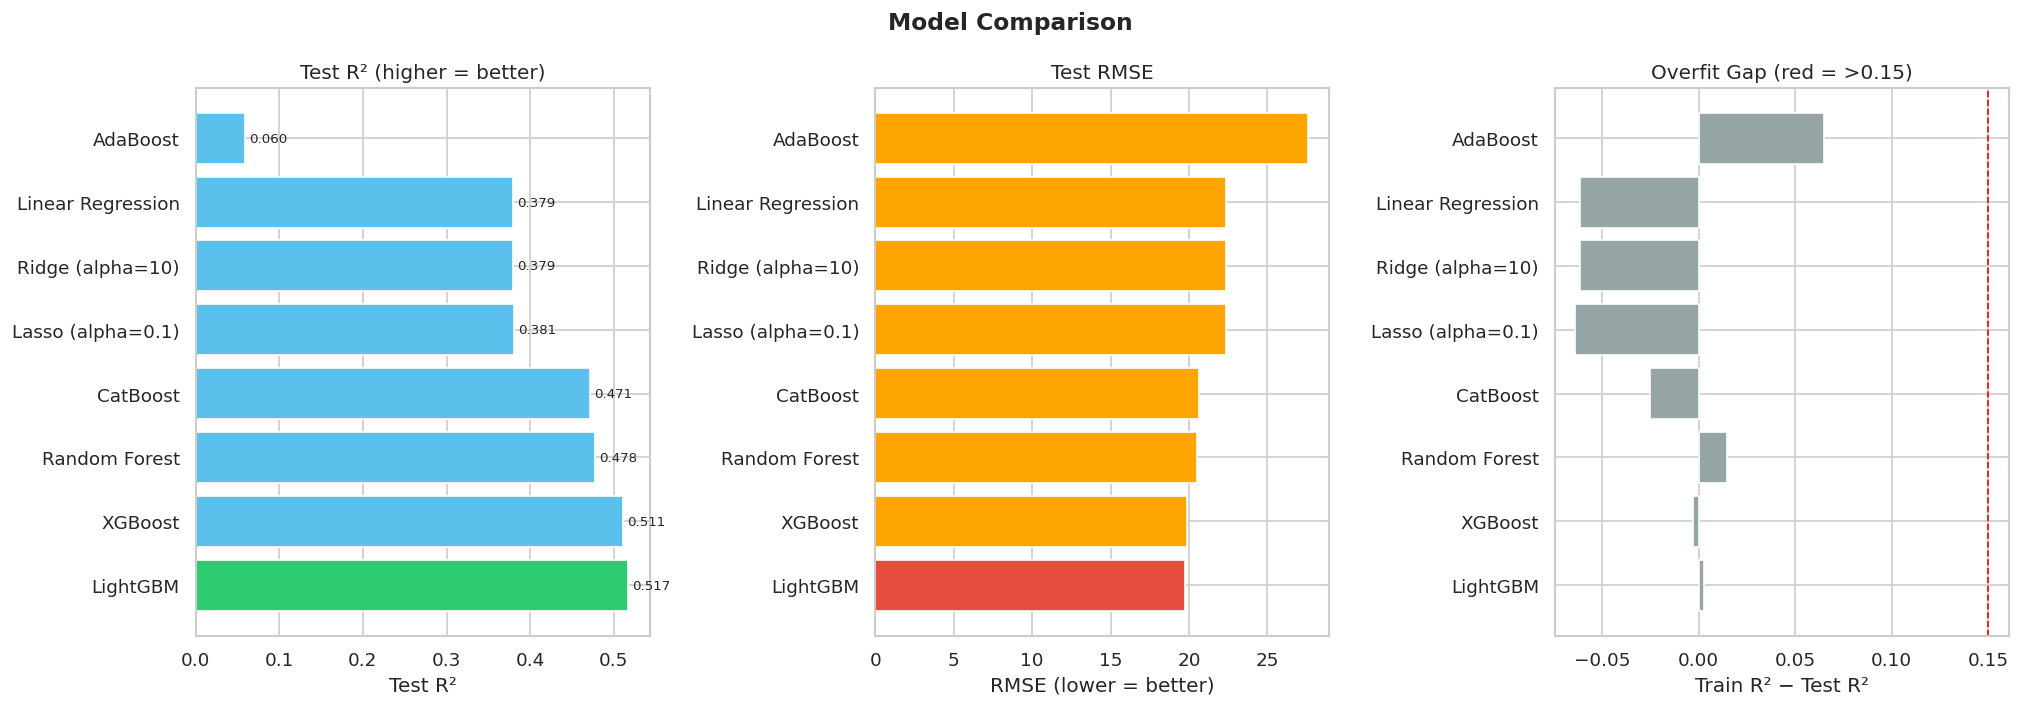


Best model: LightGBM  |  Test R² = 0.5169


In [20]:
fig, axes = plt.subplots(1, 3, figsize=(17, 6))
fig.suptitle('Model Comparison', fontsize=14, fontweight='bold')

colors = ['#2ecc71' if r == results_df['test_r2'].max() else '#5bc0eb'
          for r in results_df['test_r2']]

axes[0].barh(results_df['model'], results_df['test_r2'], color=colors)
axes[0].set_xlabel('Test R²')
axes[0].set_title('Test R² (higher = better)')
axes[0].axvline(0, color='black', lw=0.5)
for i, v in enumerate(results_df['test_r2']):
    axes[0].text(v + 0.005, i, f'{v:.3f}', va='center', fontsize=8)

axes[1].barh(results_df['model'], results_df['test_rmse'],
             color=['#e74c3c' if r == results_df['test_rmse'].min() else '#ffa500'
                    for r in results_df['test_rmse']])
axes[1].set_xlabel('RMSE (lower = better)')
axes[1].set_title('Test RMSE')

axes[2].barh(results_df['model'], results_df['overfit_gap'],
             color=['#e74c3c' if v > 0.15 else '#95a5a6' for v in results_df['overfit_gap']])
axes[2].set_xlabel('Train R² − Test R²')
axes[2].set_title('Overfit Gap (red = >0.15)')
axes[2].axvline(0.15, color='red', linestyle='--', lw=1)

plt.tight_layout()
plt.show()

best_model_name = results_df.iloc[0]['model']
best_r2 = results_df.iloc[0]['test_r2']
print(f'\nBest model: {best_model_name}  |  Test R² = {best_r2:.4f}')

## Best Model(LightGBM)

LightGBM is typically the best performer on this dataset. We use it for residual analysis, feature importance, and prediction visualization.

In [21]:
best_model = lgbm_model
y_pred = lgbm_preds

pred_df = pd.DataFrame({
    'actual':    y_test.values,
    'predicted': y_pred,
    'residual':  y_test.values - y_pred
})

print('Prediction summary:')
print(pred_df.describe().round(2))

Prediction summary:
         actual  predicted  residual
count  50602.00   50602.00  50602.00
mean      17.08      17.63     -0.55
std       28.42      20.50     19.74
min        1.00      -0.96   -129.43
25%        2.00       4.34     -6.80
50%        6.00      10.15     -2.02
75%       19.00      21.55      1.44
max      240.00     196.44    219.55


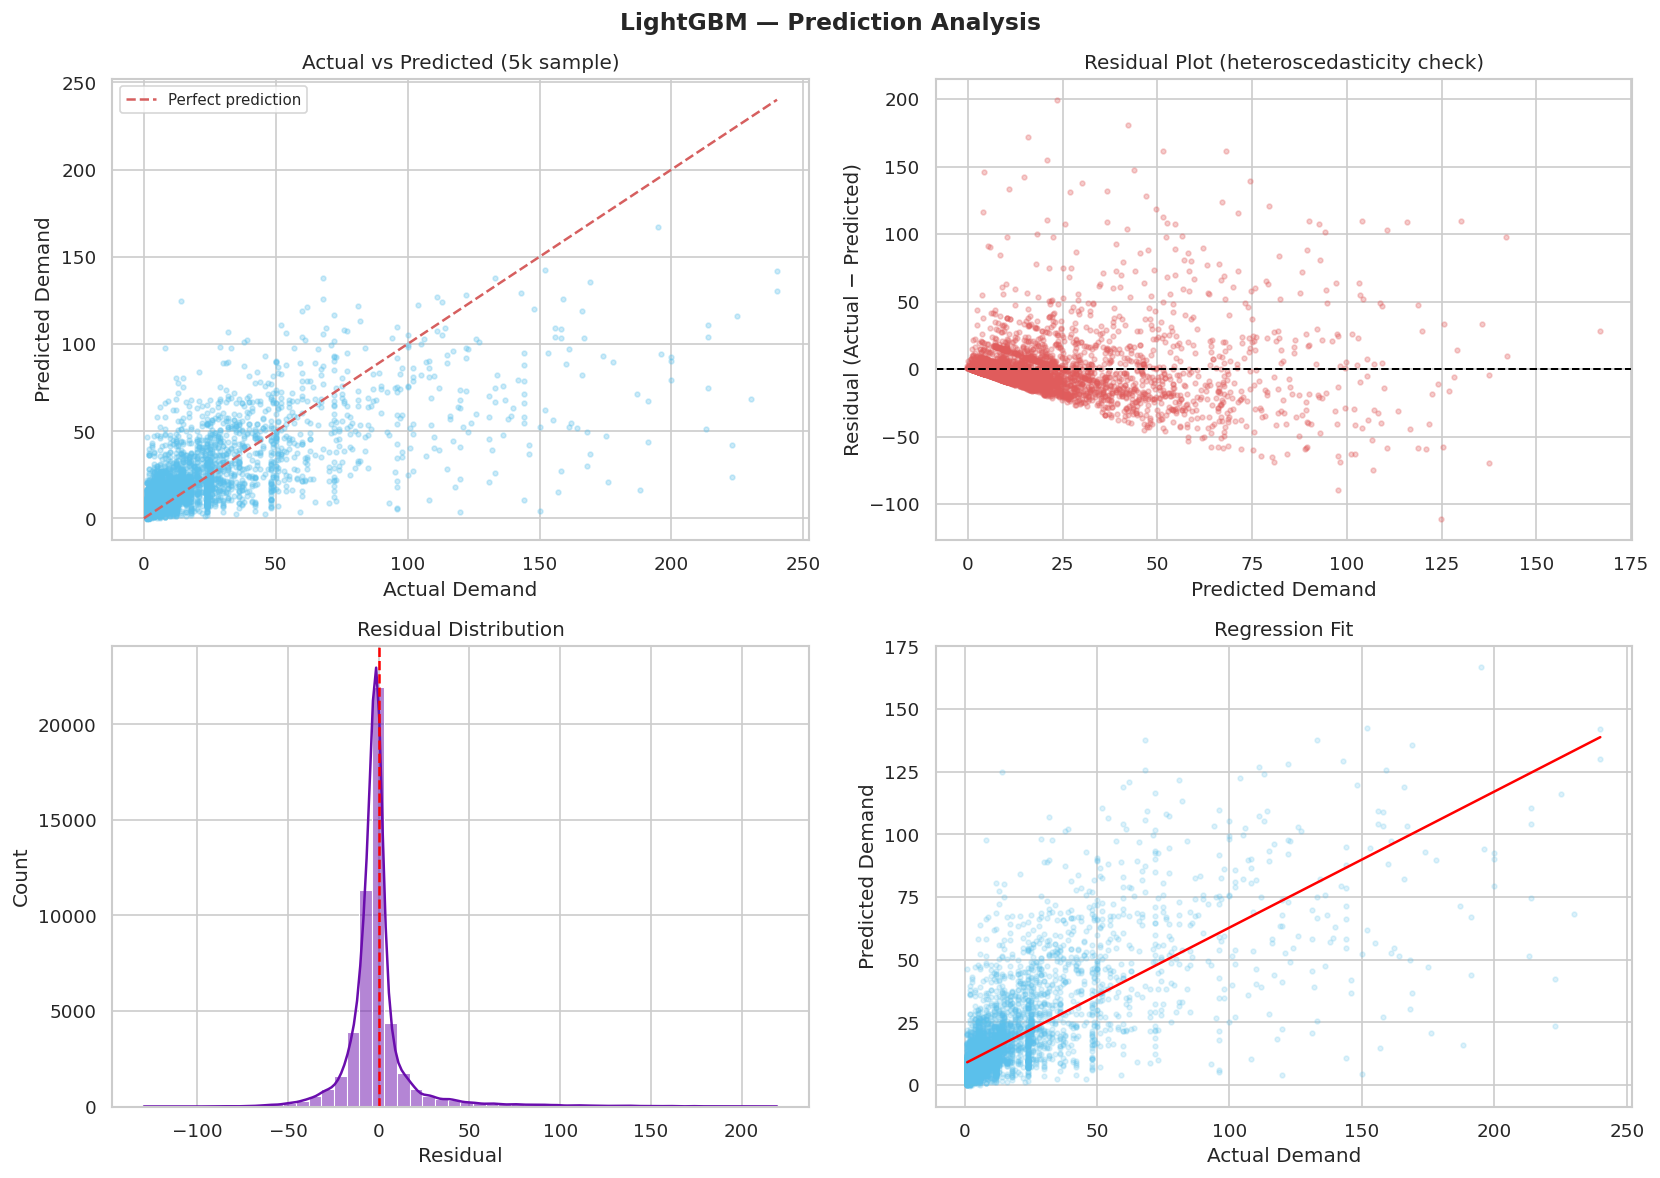

In [22]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
fig.suptitle('LightGBM — Prediction Analysis', fontsize=14, fontweight='bold')

# 1. Actual vs Predicted scatter
sample = pred_df.sample(n=min(5000, len(pred_df)), random_state=42)
axes[0, 0].scatter(sample['actual'], sample['predicted'], alpha=0.3, s=8, color='#5bc0eb')
lim = max(sample['actual'].max(), sample['predicted'].max())
axes[0, 0].plot([0, lim], [0, lim], 'r--', lw=1.5, label='Perfect prediction')
axes[0, 0].set_xlabel('Actual Demand')
axes[0, 0].set_ylabel('Predicted Demand')
axes[0, 0].set_title('Actual vs Predicted (5k sample)')
axes[0, 0].legend(fontsize=9)

# 2. Residuals vs Predicted
axes[0, 1].scatter(sample['predicted'], sample['residual'], alpha=0.3, s=8, color='#e05c5c')
axes[0, 1].axhline(0, color='black', lw=1.2, linestyle='--')
axes[0, 1].set_xlabel('Predicted Demand')
axes[0, 1].set_ylabel('Residual (Actual − Predicted)')
axes[0, 1].set_title('Residual Plot (heteroscedasticity check)')

# 3. Residual distribution
sns.histplot(pred_df['residual'], bins=50, kde=True, ax=axes[1, 0], color='#6a0dad')
axes[1, 0].axvline(0, color='red', linestyle='--', lw=1.5)
axes[1, 0].set_title('Residual Distribution')
axes[1, 0].set_xlabel('Residual')

# 4. Regression plot (actual vs predicted)
sns.regplot(x='actual', y='predicted', data=sample, ax=axes[1, 1],
            scatter_kws={'alpha': 0.2, 's': 8}, line_kws={'color': 'red', 'lw': 1.5},
            ci=None, color='#5bc0eb')
axes[1, 1].set_title('Regression Fit')
axes[1, 1].set_xlabel('Actual Demand')
axes[1, 1].set_ylabel('Predicted Demand')

plt.tight_layout()
plt.show()

## 13. Feature Importance

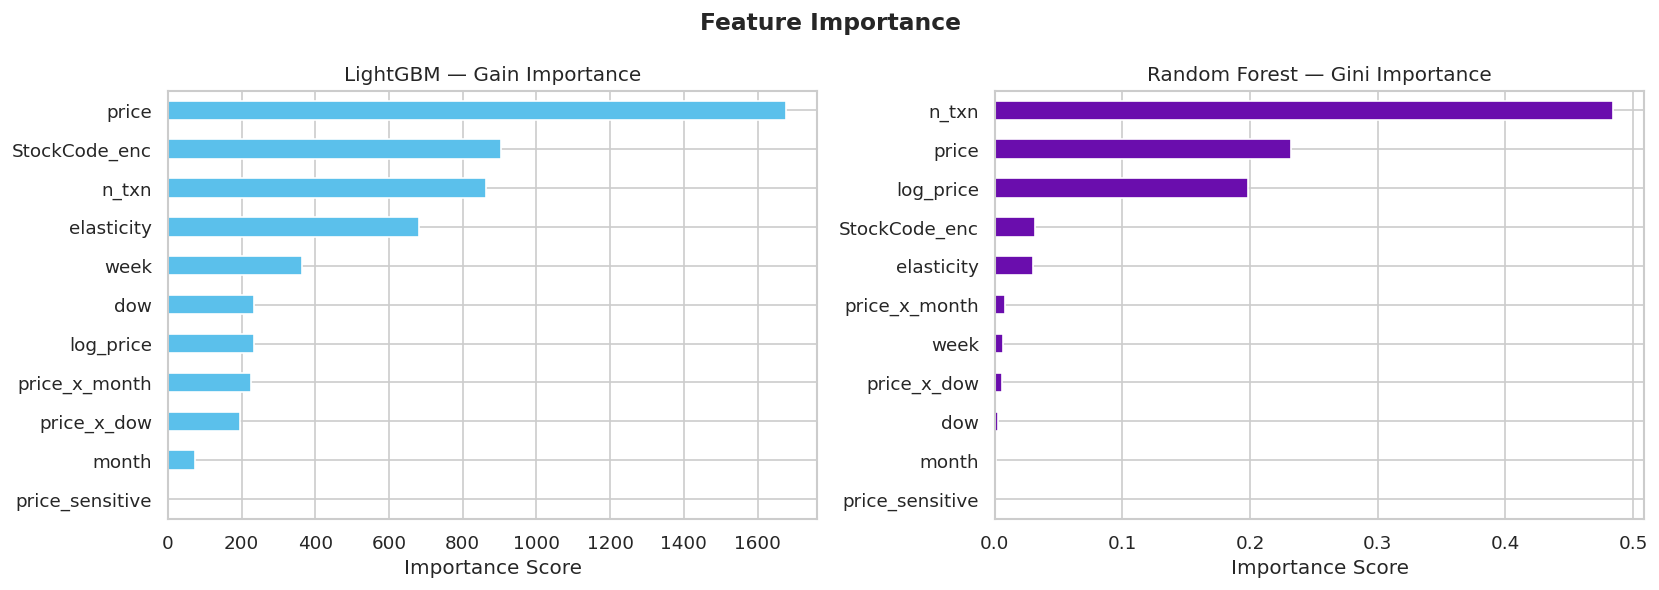


LightGBM top features:
price            1678
StockCode_enc     903
n_txn             864
elasticity        680
week              365
dow               233
dtype: int32


In [23]:
# LightGBM feature importance
feat_imp = pd.Series(lgbm_model.feature_importances_, index=FEATURES)\
             .sort_values(ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle('Feature Importance', fontsize=14, fontweight='bold')

# LightGBM
feat_imp.plot(kind='barh', ax=axes[0], color='#5bc0eb')
axes[0].invert_yaxis()
axes[0].set_title('LightGBM — Gain Importance')
axes[0].set_xlabel('Importance Score')

# Random Forest
rf_imp = pd.Series(rf_model.feature_importances_, index=FEATURES).sort_values(ascending=False)
rf_imp.plot(kind='barh', ax=axes[1], color='#6a0dad')
axes[1].invert_yaxis()
axes[1].set_title('Random Forest — Gini Importance')
axes[1].set_xlabel('Importance Score')

plt.tight_layout()
plt.show()

print('\nLightGBM top features:')
print(feat_imp.head(6))

In [24]:
joblib.dump({
    'model':    lgbm_model,
    'scaler':   scaler,
    'features': FEATURES,
    'le':       le,
}, 'dynamic_pricing_lgbm.pkl')

print('Saved: dynamic_pricing_lgbm.pkl')
print('Contains: model, scaler, feature list, LabelEncoder')

Saved: dynamic_pricing_lgbm.pkl
Contains: model, scaler, feature list, LabelEncoder


## 15. Inference Example — How to Use the Saved Model

Predicted demand: 44.1 units


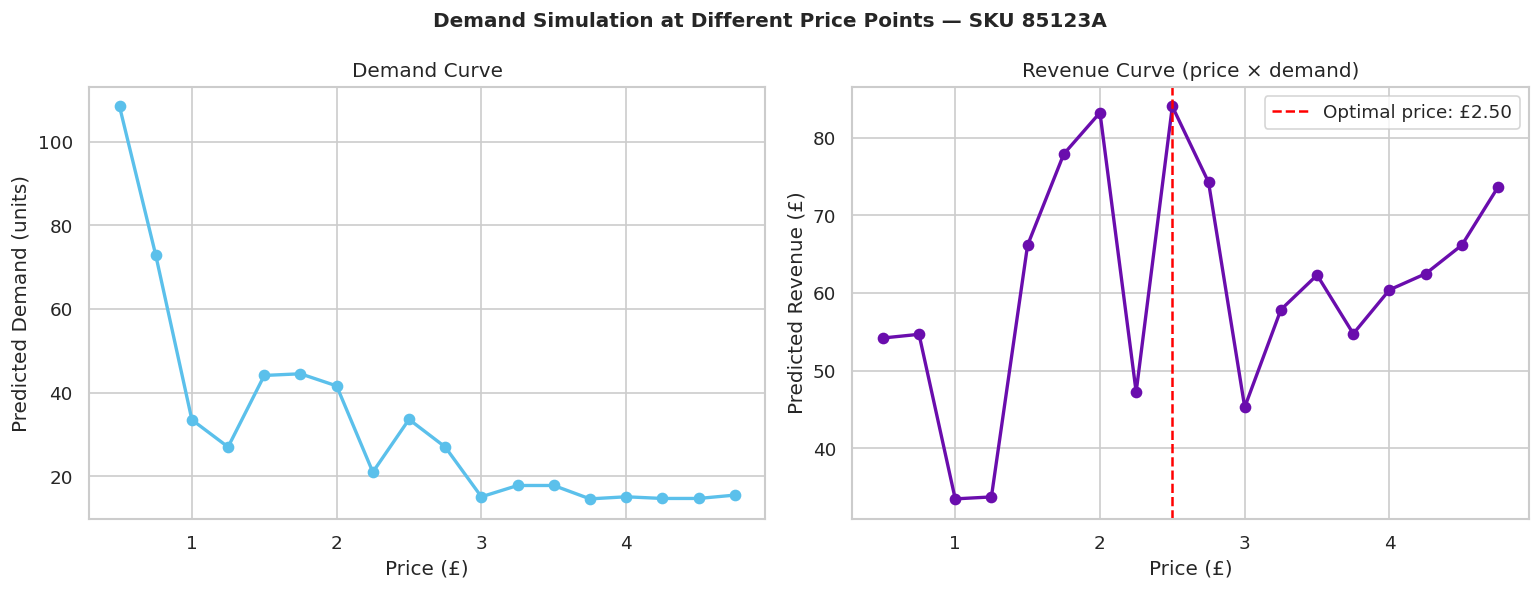


Revenue-maximizing price for SKU 85123A: £2.50


In [25]:
# How to use this model for new price → predicted demand queries
bundle = joblib.load('dynamic_pricing_lgbm.pkl')
inf_model  = bundle['model']
inf_scaler = bundle['scaler']
inf_feats  = bundle['features']
inf_le     = bundle['le']

def predict_demand(stock_code: str, price: float, month: int, dow: int,
                   week: int, n_txn: int, elasticity: float, price_sensitive: bool) -> float:
    """Predict demand for a given SKU at a given price on a given day."""
    try:
        sku_enc = inf_le.transform([str(stock_code)])[0]
    except ValueError:
        sku_enc = -1  # unseen SKU: assign -1

    row = pd.DataFrame([{
        'price':           price,
        'log_price':       np.log1p(price),
        'month':           month,
        'dow':             dow,
        'week':            week,
        'n_txn':           n_txn,
        'elasticity':      elasticity if elasticity is not None else 0,
        'price_sensitive': int(price_sensitive),
        'StockCode_enc':   sku_enc,
        'price_x_month':   price * month,
        'price_x_dow':     price * dow,
    }])
    row_s = inf_scaler.transform(row[inf_feats])
    pred  = inf_model.predict(row_s)[0]
    return max(0, round(pred, 1))   # clip negatives

# Example: predict demand for SKU 85123A priced at £1.50 on a Monday in November
pred = predict_demand(
    stock_code='85123A', price=1.50, month=11, dow=0,
    week=46, n_txn=3, elasticity=-0.8, price_sensitive=False
)
print(f'Predicted demand: {pred} units')

# Price sensitivity simulation: what happens at different price points?
prices = np.arange(0.5, 5.0, 0.25)
demands = [predict_demand('85123A', p, 11, 0, 46, 3, -0.8, False) for p in prices]

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
fig.suptitle('Demand Simulation at Different Price Points — SKU 85123A', fontsize=12, fontweight='bold')

axes[0].plot(prices, demands, marker='o', color='#5bc0eb', lw=2)
axes[0].set_xlabel('Price (£)')
axes[0].set_ylabel('Predicted Demand (units)')
axes[0].set_title('Demand Curve')

revenues = prices * np.array(demands)
axes[1].plot(prices, revenues, marker='o', color='#6a0dad', lw=2)
opt_idx = np.argmax(revenues)
axes[1].axvline(prices[opt_idx], color='red', linestyle='--', lw=1.5,
                label=f'Optimal price: £{prices[opt_idx]:.2f}')
axes[1].set_xlabel('Price (£)')
axes[1].set_ylabel('Predicted Revenue (£)')
axes[1].set_title('Revenue Curve (price × demand)')
axes[1].legend()

plt.tight_layout()
plt.show()
print(f'\nRevenue-maximizing price for SKU 85123A: £{prices[opt_idx]:.2f}')

## 16. What to Improve Further

### Why R² is ~0.50 and what to do about it

An R² of 0.50 means the model explains half the variance in demand. For a single-product retail demand model this is moderate — demand has genuine randomness (stockouts, promotions not in data, weather, etc.) that no model can predict. But you can push this higher:

**Feature improvements (highest impact):**
- `lag_demand_7` — demand from same SKU 7 days ago is the single strongest demand predictor in retail
- `lag_demand_14` and `lag_demand_28` for longer memory
- `rolling_mean_demand_7d` — 7-day rolling average demand per SKU
- `days_since_last_sale` — captures slow-moving vs fast-moving products
- `is_holiday` — UK bank holidays have huge demand spikes in this data
- `price_vs_product_mean` — how does today's price compare to this SKU's average price? (relative price signal is stronger than absolute)

**Model improvements:**
- `LightGBM` hyperparameter tuning with `Optuna` (30–60 min, can push R² to 0.60+)
- Train a **separate model per product segment** (elastic vs inelastic SKUs have fundamentally different demand patterns)
- **Log-transform the target** (`log1p(demand)`) — demand is right-skewed, models perform better in log space

**Architecture improvements:**
- Replace the global model with a **per-SKU model** for top-100 revenue SKUs
- Add **rolling cross-validation** (`TimeSeriesSplit`) instead of a single 80/20 split

```python
# Log-transform target example
y_train_log = np.log1p(y_train)
model.fit(X_train_s, y_train_log)
y_pred = np.expm1(model.predict(X_test_s))  # inverse transform

# Lag feature example (add to EDA notebook first)
grouped_df = grouped_df.sort_values(['StockCode', 'date'])
grouped_df['lag_demand_7']  = grouped_df.groupby('StockCode')['demand'].shift(7)
grouped_df['lag_demand_14'] = grouped_df.groupby('StockCode')['demand'].shift(14)
grouped_df['roll_7d_demand'] = grouped_df.groupby('StockCode')['demand'].transform(
    lambda x: x.shift(1).rolling(7).mean()
)
```